# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

The core examples use the assignment's **illustrative** monthly rainfall totals (mm) for Kampala, Gulu and Mbarara. Crop suitability is a rainfall-only screening aid, not agronomic advice: the monthly bands are transparent heuristics informed by FAO crop-water guidance, not crop-specific guarantees. The extension retrieves 11 years of NASA POWER data for Kampala and compares rainfall totals by calendar month.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

from src.rainfall import (
    MONTH_NAMES,
    CropRule,
    Region,
    classify_crop_suitability,
    cosine_similarity,
    detect_rainy_seasons,
    fetch_nasa_power_monthly_rainfall,
    region_comparison_matrices,
    scipy_cosine_similarity,
)

## Regions and annual rainfall summaries

Regional names and single-year values are supplied by the assignment. A one-year monthly profile cannot represent interannual variability or climate normals.

In [2]:
rainfall_data = {
    "Kampala": [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130],
    "Gulu": [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90],
}
regions = {name: Region(name, values) for name, values in rainfall_data.items()}
summary = pd.DataFrame.from_dict(
    {
        name: {
            "annual_total_mm": region.annual_total(),
            "monthly_mean_mm": region.monthly_mean(),
            "wettest_month": region.wettest_month()[0],
            "wettest_month_mm": region.wettest_month()[1],
            "driest_month": region.driest_month()[0],
            "driest_month_mm": region.driest_month()[1],
            "monthly_coefficient_of_variation": region.coefficient_of_variation(),
        }
        for name, region in regions.items()
    },
    orient="index",
)
display(summary.round(2))

,annual_total_mm,monthly_mean_mm,wettest_month,wettest_month_mm,driest_month,driest_month_mm,monthly_coefficient_of_variation
Kampala,1600.0,133.33,May,220.0,September,60.0,0.37
Gulu,1388.0,115.67,August,215.0,January,8.0,0.61
Mbarara,1040.0,86.67,April,140.0,July,20.0,0.42


## Crop rainfall rules and monthly classification

FAO guidance emphasizes that crop water need depends on climate, crop type, growth stage and effective rainfall. The following monthly screening bands are deliberately simplified operational assumptions for visualization: maize 80–200 mm/month, beans 50–150 mm/month and coffee 100–250 mm/month. The ranges are approximate monthly allocations of indicative crop water demand and are **not** FAO-prescribed thresholds. Values below a band are flagged as drought risk and values above as potential excess/waterlogging risk; actual suitability also depends on soil drainage, planting date, crop stage, temperature and rainfall intensity.

In [3]:
crop_rules = [
    CropRule("maize", minimum_mm=80, maximum_mm=200),
    CropRule("beans", minimum_mm=50, maximum_mm=150),
    CropRule("coffee", minimum_mm=100, maximum_mm=250),
]
crop_classifications = classify_crop_suitability(regions, crop_rules)
display(crop_classifications.pivot_table(
    index=["region", "month"], columns="crop", values="classification", aggfunc="first"
))

crop                           beans           coffee              maize
region  month                                                           
Gulu    April      Waterlogging risk  Good for coffee     Good for maize
        August     Waterlogging risk  Good for coffee  Waterlogging risk
        December        Drought risk     Drought risk       Drought risk
        February        Drought risk     Drought risk       Drought risk
        January         Drought risk     Drought risk       Drought risk
        July       Waterlogging risk  Good for coffee     Good for maize
        June          Good for beans  Good for coffee     Good for maize
        March         Good for beans     Drought risk       Drought risk
        May        Waterlogging risk  Good for coffee     Good for maize
        November      Good for beans     Drought risk       Drought risk
        October       Good for beans  Good for coffee     Good for maize
        September  Waterlogging risk  Good for coffee     Good for maize
Kampala April      Waterlogging risk  Good for coffee     Good for maize
        August        Good for beans     Drought risk       Drought risk
        December      Good for beans  Good for coffee     Good for maize
        February      Good for beans  Good for coffee     Good for maize
        January       Good for beans  Good for coffee     Good for maize
        July          Good for beans     Drought risk     Good for maize
        June       Waterlogging risk  Good for coffee     Good for maize
        March      Waterlogging risk  Good for coffee     Good for maize
        May        Waterlogging risk  Good for coffee  Waterlogging risk
        November      Good for beans  Good for coffee     Good for maize
        October       Good for beans  Good for coffee     Good for maize
        September     Good for beans     Drought risk       Drought risk
Mbarara April         Good for beans  Good for coffee     Good for maize
        August        Good for beans     Drought risk       Drought risk
        December      Good for beans     Drought risk     Good for maize
        February      Good for beans     Drought risk     Good for maize
        January       Good for beans     Drought risk       Drought risk
        July            Drought risk     Drought risk       Drought risk
        June            Drought risk     Drought risk       Drought risk
        March         Good for beans  Good for coffee     Good for maize
        May           Good for beans     Drought risk     Good for maize
        November      Good for beans  Good for coffee     Good for maize
        October       Good for beans  Good for coffee     Good for maize
        September     Good for beans  Good for coffee     Good for maize

## Correct cosine similarity and verify with SciPy

`math.cos` expects one angle in radians; it is not a vector comparison. Vector cosine similarity is `dot(x, y) / (||x|| ||y||)`. SciPy's `spatial.distance.cosine` returns the corresponding cosine **distance**, so similarity equals one minus that distance.

In [4]:
kampala_rain = regions["Kampala"].rainfall_mm
gulu_rain = regions["Gulu"].rainfall_mm
numpy_similarity = cosine_similarity(kampala_rain, gulu_rain)
scipy_similarity = scipy_cosine_similarity(kampala_rain, gulu_rain)
print(f"NumPy dot/norm similarity: {numpy_similarity:.6f}")
print(f"1 - SciPy cosine distance: {scipy_similarity:.6f}")
assert np.isclose(numpy_similarity, scipy_similarity)

NumPy dot/norm similarity: 0.786609
1 - SciPy cosine distance: 0.786609


## Pairwise regional similarity and distance matrices

Cosine similarity compares seasonal profile direction, not magnitude. If every month in one region is twice as wet as another (`y = 2x`), their cosine similarity is still 1 even though absolute rainfall totals and Euclidean distance differ. Pearson correlation similarly centers and scales values; Euclidean distance preserves absolute differences in millimetres.

In [5]:
comparison_matrices = region_comparison_matrices(regions)
for metric, matrix in comparison_matrices.items():
    print(metric)
    display(matrix.round(3))

scaled_profile = 2 * regions["Mbarara"].rainfall_mm
print(
    "Scale illustration: cosine similarity =",
    round(cosine_similarity(regions["Mbarara"].rainfall_mm, scaled_profile), 3),
    "while Euclidean distance =",
    round(float(np.linalg.norm(regions["Mbarara"].rainfall_mm - scaled_profile)), 1),
    "mm",
)

Cosine similarity


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000


Pearson correlation


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000


Euclidean distance (mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.4
Gulu,315.268,0.000,312.8
Mbarara,250.400,312.800,0.0


Scale illustration: cosine similarity = 1.0 while Euclidean distance = 326.2 mm


## Rainy-season peak detection and climate-zone comparison

`scipy.signal.find_peaks` is applied to a circularly repeated annual profile. The 20 mm prominence filter and two-month minimum separation reduce small local fluctuations; these choices affect the classification. Uganda is broadly described as having more bimodal rainfall in central/southern areas and more unimodal regimes toward the north. Compare that broad pattern with the detected results, but treat disagreement as a limitation of single-year illustrative inputs and a simple peak rule—not evidence that the climate-zone description is wrong.

In [6]:
season_rows = []
season_results = {}
for name, region in regions.items():
    result = detect_rainy_seasons(region, minimum_prominence_mm=20, minimum_peak_distance_months=2)
    season_results[name] = result
    season_rows.append({
        "Region": name,
        "Detected pattern": result["classification"],
        "Peak months": ", ".join(result["peak_months"]) or "None",
        "Peak prominence (mm)": result["peak_prominences_mm"],
    })
display(pd.DataFrame(season_rows).set_index("Region"))

,Detected pattern,Peak months,Peak prominence (mm)
Region,,,
Kampala,Unimodal,May,{4: 160.0}
Gulu,Bimodal,"May, August","{4: 45.0, 7: 207.0}"
Mbarara,Bimodal,"April, October","{3: 120.0, 9: 55.0}"


For the supplied monthly series, the prominence rule identifies Kampala as unimodal, while Gulu and Mbarara are bimodal. Mbarara agrees with the broad southern bimodal pattern. Kampala's result does not; the secondary year-end rise is too small to pass the prominence threshold. Gulu's illustrative two-peak pattern also differs from the broad expectation of a more unimodal north. The one-year example, local rainfall variation, broad geographic labels and algorithm settings limit this comparison.

## Visualisations: rainfall lines and crop-suitability heatmaps

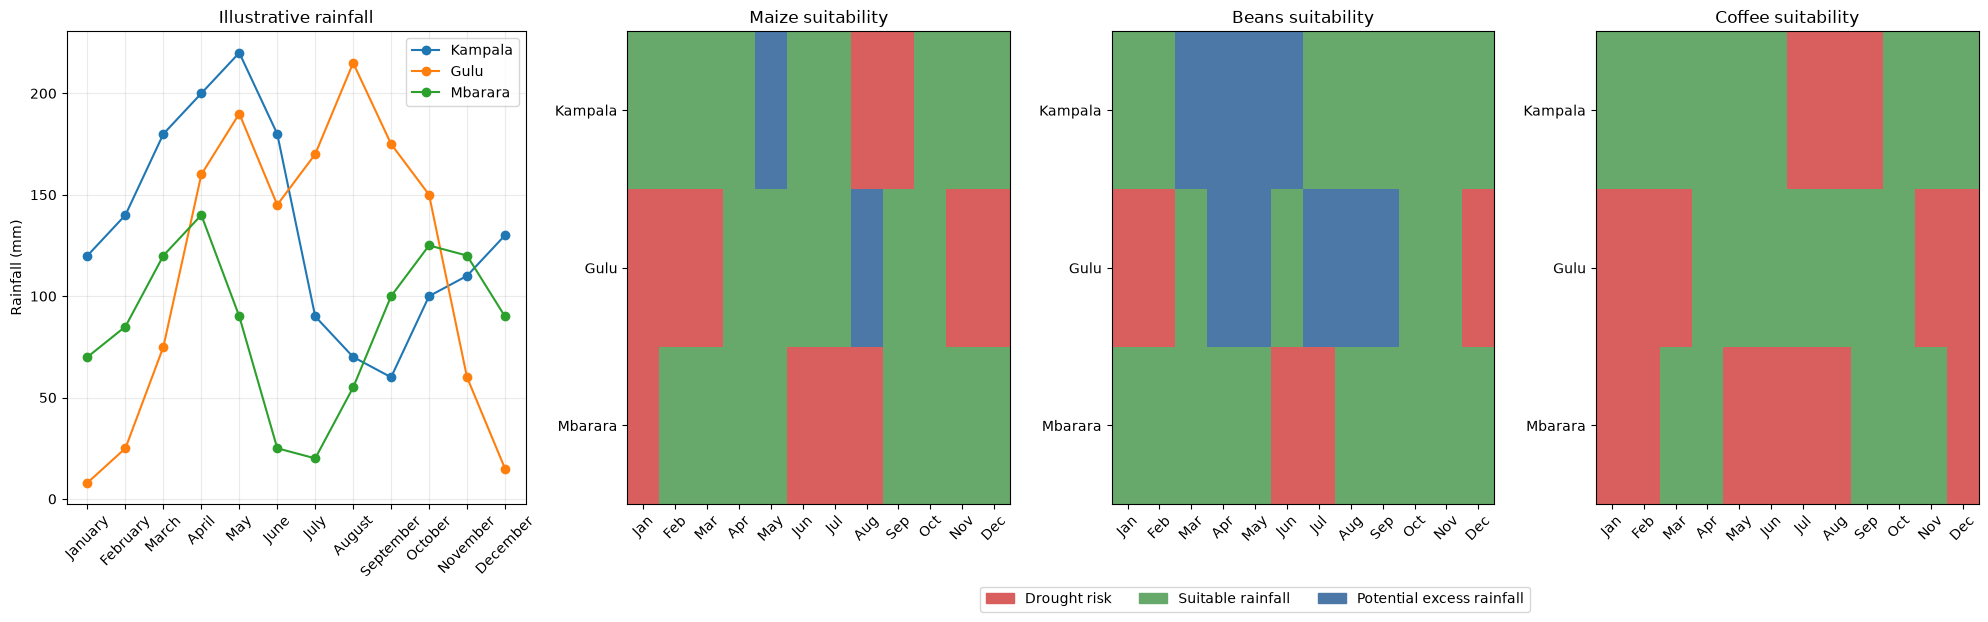

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 6), gridspec_kw={"width_ratios": [1.2, 1, 1, 1]})
for name, region in regions.items():
    axes[0].plot(MONTH_NAMES, region.rainfall_mm, marker="o", label=name)
axes[0].set_title("Illustrative rainfall")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.25)
axes[0].legend()

status_codes = {"Drought risk": 0, "Good": 1, "Waterlogging risk": 2}
colors = ["#d95f5f", "#67a96b", "#4c78a8"]
for crop_index, rule in enumerate(crop_rules):
    suitability = np.array([
        [
            status_codes.get(
                "Good" if rule.classify(float(regions[name].rainfall_mm[month])).startswith("Good for")
                else rule.classify(float(regions[name].rainfall_mm[month])),
                0,
            )
            for month in range(12)
        ]
        for name in regions
    ])
    crop_ax = axes[crop_index + 1]
    crop_ax.imshow(suitability, aspect="auto", cmap=ListedColormap(colors), vmin=-0.5, vmax=2.5)
    crop_ax.set_yticks(range(len(regions)), list(regions))
    crop_ax.set_xticks(range(12), [month[:3] for month in MONTH_NAMES], rotation=45)
    crop_ax.set_title(f"{rule.crop_name.title()} suitability")
legend_handles = [Patch(color=color, label=label) for color, label in zip(colors, ["Drought risk", "Suitable rainfall", "Potential excess rainfall"])]
fig.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.63, -0.04), ncol=3)
fig.tight_layout()
plt.show()

## Farmer advisory: Gulu maize (under 200 words)

The illustrative Gulu profile suggests the most promising maize rainfall window begins around April, when monthly rainfall rises into the screening band, and continues through July. Check the actual onset of sustained rains before planting rather than relying on a fixed calendar date. The May–June profile is within the simple 80–200 mm/month band; July is also within it, while August exceeds the screening range and may bring excess-moisture concerns. Consider staggering planting or using well-drained fields to reduce exposure to uneven onset and heavy rainfall. Rainfall alone cannot determine suitability: confirm soil drainage, seed maturity, temperature, pest pressure and local extension guidance. The figures are illustrative monthly totals, not a forecast for this season.

## Extension: NASA POWER rainfall variability (2014–2024)

The NASA POWER monthly endpoint returns corrected precipitation as a monthly mean daily rate (mm/day). The helper converts each month's rate to an approximate monthly accumulation by multiplying by the calendar month length. The resulting 11 years are shown as month-by-month boxplots. POWER is a gridded reanalysis/product, not a local rain-gauge observation; station validation is recommended.

Retrieved 132 monthly observations; saved to data\nasa_power_kampala_monthly_2014_2024.csv


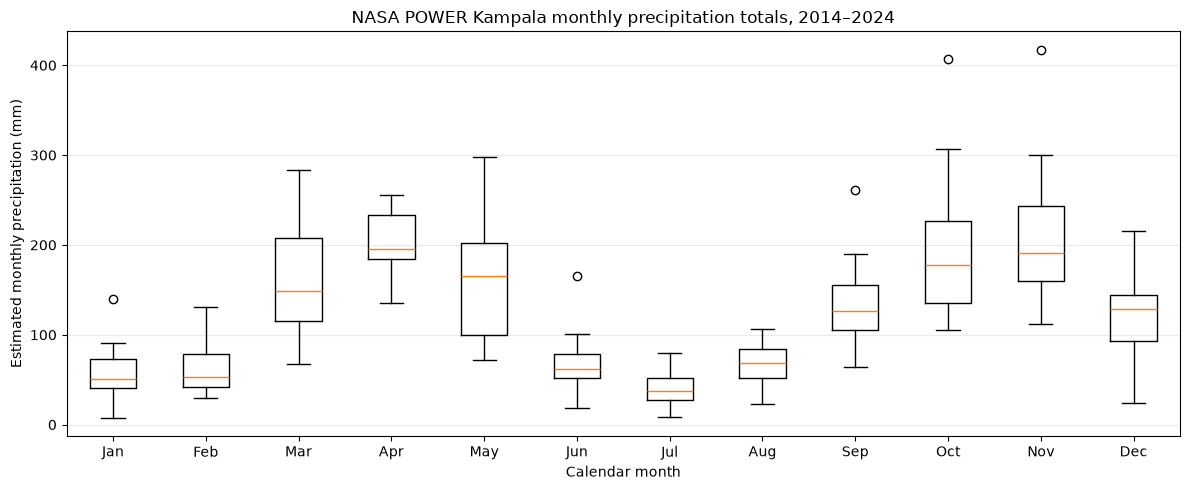

In [8]:
nasa_rainfall = fetch_nasa_power_monthly_rainfall(
    latitude=0.31,
    longitude=32.58,
    start_year=2014,
    end_year=2024,
)
data_directory = Path("data")
data_directory.mkdir(exist_ok=True)
nasa_csv_path = data_directory / "nasa_power_kampala_monthly_2014_2024.csv"
nasa_rainfall.to_csv(nasa_csv_path, index=False)
nasa_rainfall["month_name"] = nasa_rainfall["month"].map(lambda month: MONTH_NAMES[month - 1])
print(f"Retrieved {len(nasa_rainfall)} monthly observations; saved to {nasa_csv_path}")
fig, ax = plt.subplots(figsize=(12, 5))
boxplot_data = [
    nasa_rainfall.loc[nasa_rainfall["month"] == month, "rainfall_mm"].to_numpy()
    for month in range(1, 13)
]
ax.boxplot(boxplot_data, tick_labels=[month[:3] for month in MONTH_NAMES])
ax.set_title("NASA POWER Kampala monthly precipitation totals, 2014–2024")
ax.set_ylabel("Estimated monthly precipitation (mm)")
ax.set_xlabel("Calendar month")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## Findings & Limitations

The illustrative annual totals differ across Kampala, Gulu and Mbarara, and their monthly coefficients of variation show marked within-year seasonality. Cosine similarity emphasizes profile shape: multiplying all monthly values by a constant leaves it unchanged, so it should be paired with absolute totals or Euclidean distance. Pearson correlation also focuses on co-movement, while Euclidean distance retains scale. In the automatic peak results, Mbarara is bimodal, but Kampala is classified as unimodal and Gulu as bimodal. This only partly matches the broad Uganda pattern of bimodal central/southern rainfall and more unimodal northern regimes. It demonstrates how a single illustrative year and a fixed prominence filter can misrepresent regional climate structure.

The crop bands are educational rainfall screens, not empirical yield thresholds or planting prescriptions. Rainfall does not equal effective crop water: runoff, soil storage, evapotranspiration, drainage, crop stage, variety and temperature matter. An above-band month is labelled potential waterlogging risk, not a diagnosis. NASA POWER supplies gridded corrected precipitation, and multiplying its monthly mean daily rate by days yields an approximate monthly total; these data may differ from a local gauge and should be checked before operational use. The 2014–2024 month-wise boxplots describe variation at one point and do not establish trends or causal crop impacts. For reliable seasonal decisions, use longer station records, local planting calendars and field-level soil and crop information.

## References

- Course assignment prompt for the illustrative monthly rainfall data and project requirements.
- Brouwer, C. & Heibloem, M. (1986), FAO, *Irrigation Water Management: Irrigation Water Needs*, especially the explanation that water needs depend on climate, crop type and crop growth stage: [Chapter 1](https://www.fao.org/4/s2022e/s2022e05.htm) and [Chapter 3](https://www.fao.org/4/s2022e/s2022e07.htm). The notebook's monthly crop bands are stated assumptions, not published FAO cutoffs.
- Allen, R. G., Pereira, L. S., Raes, D. & Smith, M. (1998), FAO Irrigation and Drainage Paper 56, *Crop Evapotranspiration*: [FAO publication](https://www.fao.org/4/x0490e/x0490e00.htm).
- Uganda National Meteorological Authority, [Climate of Uganda](https://www.unma.go.ug/climate-of-uganda/), for the broad regional rainfall-season context.
- NASA POWER, [Monthly and Annual API documentation](https://power.larc.nasa.gov/docs/services/api/temporal/monthly/) and [POWER Data Access Viewer](https://power.larc.nasa.gov/data-access-viewer/). Data requested for Kampala (0.31°N, 32.58°E), 2014–2024, parameter `PRECTOTCORR`, community `AG`.
- SciPy documentation: [`scipy.signal.find_peaks`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html) and [`scipy.spatial.distance.cosine`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html).
- The core monthly rainfall series is illustrative and supplied in the course prompt; crop thresholds are transparent screening assumptions.